# Gaspype thermodynamics in difflow (#492)

[Gaspype](https://www.gaspype.org/) (DLR Institute of Future Fuels, MIT licence) is a
pure-Python library for ideal-gas thermodynamics and chemical equilibrium. It has
NASA-9 data for about a thousand gas-phase species, and it can use NumPy or JAX as
its array backend.

Can difflow use it? Yes, in two ways:

1. **Gaspype on its own.** Its `equilibrium` is fast and vectorised. With
   `backend="jax"` it also differentiates, but only eagerly. Under `jax.jit` its
   Newton loop becomes a `lax.while_loop`, and reverse mode cannot differentiate
   that, so `jax.jit(jax.grad(...))` raises.
2. **Gaspype's data in difflow's solver.** `difflow.gaspype_import.GaspypeThermo`
   turns a list of gaspype species into the thermo object `GibbsReactor` takes.
   difflow's element-potential solver gets its gradients by implicit
   differentiation, so jit, grad and flowsheet optimisation all work.

This notebook covers:

1. Gaspype on its own: steam-methane-reforming equilibrium over a temperature sweep.
2. Gaspype's JAX backend and where it stops.
3. `GaspypeThermo` in a `GibbsReactor`, checked against gaspype's own solver.
4. Gradients: compiled sensitivities of the reformer equilibrium.
5. Adiabatic flame temperature of methane in air from gaspype's species data,
   and its exact slope with respect to the equivalence ratio.
6. A reformer and water-gas-shift train, optimised by gradient.

Gaspype is optional: `pip install gaspype` or `pip install "difflow[gaspype]"`.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import gaspype as gp

from difflow import GibbsReactor, GibbsReactorParams, make_stream
from difflow.gaspype_import import GaspypeThermo, list_available_species

print("gaspype", gp.__version__, "-", len(list_available_species()), "gas-phase species")

gaspype 1.1.6 - 1057 gas-phase species


## 1. Gaspype on its own

A `fluid_system` fixes the species. A `fluid` is a composition over them, and
`gp.equilibrium` returns the equilibrium fluid. Arrays of temperature broadcast, so
one call solves a whole sweep.

Here 1 mol CH4 and 3 mol H2O (steam-to-carbon S/C = 3) are taken to equilibrium
at 1 bar.

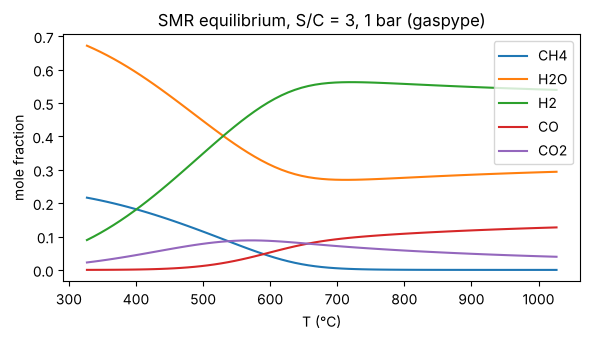

In [2]:
SMR = ["CH4", "H2O", "H2", "CO", "CO2"]
fs = gp.fluid_system(SMR)
feed = gp.fluid({"CH4": 1.0, "H2O": 3.0}, fs)

T_sweep = np.linspace(600.0, 1300.0, 71)
eq = gp.equilibrium(feed, T_sweep, 1e5)          # one vectorised call
x_gp = eq.array_fractions                        # (71, 5)

fig, ax = plt.subplots(figsize=(6, 3.5))
for i, s in enumerate(SMR):
    ax.plot(T_sweep - 273.15, x_gp[:, i], label=s)
ax.set(xlabel="T (°C)", ylabel="mole fraction", title="SMR equilibrium, S/C = 3, 1 bar (gaspype)")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Gaspype's JAX backend

With `backend="jax"`, the arrays become `jax.numpy` arrays. An eager `jax.grad`
differentiates through the unrolled Newton iterations, and it matches a finite
difference. Under `jax.jit` the iteration is a `lax.while_loop`, and reverse mode
through a while loop is not defined in JAX.

In [3]:
fs_jax = gp.fluid_system(SMR, backend="jax")

def x_h2_gaspype(T):
    eq = gp.equilibrium(gp.fluid({"CH4": 1.0, "H2O": 3.0}, fs_jax), T, 1e5)
    return eq.array_fractions[SMR.index("H2")]

h = 1e-2
print("eager grad      :", float(jax.grad(x_h2_gaspype)(1000.0)))
print("finite diff     :", float((x_h2_gaspype(1000.0 + h) - x_h2_gaspype(1000.0 - h)) / (2 * h)))
try:
    jax.jit(jax.grad(x_h2_gaspype))(1000.0)
except ValueError as e:
    print("jit(grad) fails :", str(e).splitlines()[0])

eager grad      : -1.8393047819920127e-05


finite diff     : -1.8407170332412903e-05
jit(grad) fails : Reverse-mode differentiation does not work for lax.while_loop or lax.fori_loop with dynamic start/stop values. Try using lax.scan, or using fori_loop with static start/stop.


So gaspype's own solver is good for forward sweeps and quick eager gradients. It
cannot sit inside a compiled, differentiated difflow model.

## 3. Gaspype data in difflow's `GibbsReactor`

`GaspypeThermo(species)` exposes gaspype's data the way `GibbsReactor` wants it:
`names`, `gibbs(T)`, `enthalpy(T)` and `ELEMENTS`. By default (`method="nasa9"`) it
evaluates the NASA-9 polynomials in `jax.numpy`, so H and G are smooth in T.
`method="table"` instead uses gaspype's public `fluid_system`, which interpolates
linearly on a 1 K table. That table makes dG/dT piecewise constant.

Species names are gaspype's, and they become the stream keys (`F_CH4`, ...).

In [4]:
th = GaspypeThermo(SMR)
print(th.names, {e: v.tolist() for e, v in th.ELEMENTS.items()})

def reformer(T, P=1e5, S_C=3.0):
    inlet = make_stream({"CH4": 1.0, "H2O": S_C}, T=900.0, P=P)
    return GibbsReactor(GibbsReactorParams(thermo=th, T_out=T))(inlet)

out, info = reformer(1000.0)
print("converged:", bool(info["converged"]), " duty:", float(info["heat_duty"]) / 1e3, "kW per mol/s CH4")

('CH4', 'H2O', 'H2', 'CO', 'CO2') {'C': [1.0, 0.0, 0.0, 1.0, 1.0], 'H': [4.0, 2.0, 2.0, 0.0, 0.0], 'O': [0.0, 1.0, 0.0, 1.0, 2.0]}


converged: True  duty: 227.00842072761012 kW per mol/s CH4


The two solvers use the same species data. Gaspype's 1 K table is exact at whole
kelvins, which is where this sweep lands, so the equilibria agree to solver tolerance.
Between whole kelvins, the table's linear interpolation differs from the polynomials
by about 0.1 J/mol.

In [5]:
def fractions(T):
    out, _ = reformer(T)
    n = jnp.array([out[f"F_{s}"] for s in SMR])
    return n / n.sum()

x_df = jax.jit(jax.vmap(fractions))(jnp.asarray(T_sweep))
print("max |x_difflow - x_gaspype| over the sweep:", float(jnp.max(jnp.abs(x_df - x_gp))))

max |x_difflow - x_gaspype| over the sweep: 9.492406860545088e-15


## 4. Compiled gradients

difflow gets dz/dθ from one Newton correction at the converged point, the implicit
function theorem. It does not unroll the solve, so the derivative of the H2 fraction
with respect to T, P and S/C can be compiled. It matches a central difference.

The check is at 1050 K, not 1000 K. Most species switch NASA-9 polynomials at
1000 K, and the two fits do not quite meet there: G steps by about 0.01-0.02 J/mol.
A ±0.01 K difference that straddles the join measures that step, not the slope.

In [6]:
def x_h2(T, P, S_C):
    out, _ = reformer(T, P, S_C)
    n = sum(out[f"F_{s}"] for s in SMR)
    return out["F_H2"] / n

T0 = 1050.0
g = jax.jit(jax.grad(x_h2, argnums=(0, 1, 2)))(T0, 1e5, 3.0)
fd = [(x_h2(T0 + 1e-2, 1e5, 3.0) - x_h2(T0 - 1e-2, 1e5, 3.0)) / 2e-2,
      (x_h2(T0, 1e5 + 10.0, 3.0) - x_h2(T0, 1e5 - 10.0, 3.0)) / 20.0,
      (x_h2(T0, 1e5, 3.0 + 1e-5) - x_h2(T0, 1e5, 3.0 - 1e-5)) / 2e-5]
for name, a, b in zip(["dx/dT (1/K)", "dx/dP (1/Pa)", "dx/d(S/C)"], g, fd):
    print(f"{name:13s} jit(grad) = {float(a): .6e}   central diff = {float(b): .6e}")

dx/dT (1/K)   jit(grad) = -8.687206e-05   central diff = -8.687206e-05
dx/dP (1/Pa)  jit(grad) = -2.626973e-08   central diff = -2.626973e-08
dx/d(S/C)     jit(grad) = -7.267835e-02   central diff = -7.267835e-02


## 5. Adiabatic flame temperature

Gaspype's database supplies the radicals and minor species a flame needs. Here
methane burns in air (O2 + 3.76 N2) at equivalence ratio φ. The reactor is
adiabatic, so the outlet temperature is an unknown of the Newton solve. `jax.vmap` of
`jax.grad` gives the exact slope dT_ad/dφ along the curve.

peak T_ad = 2232 K at phi = 1.04


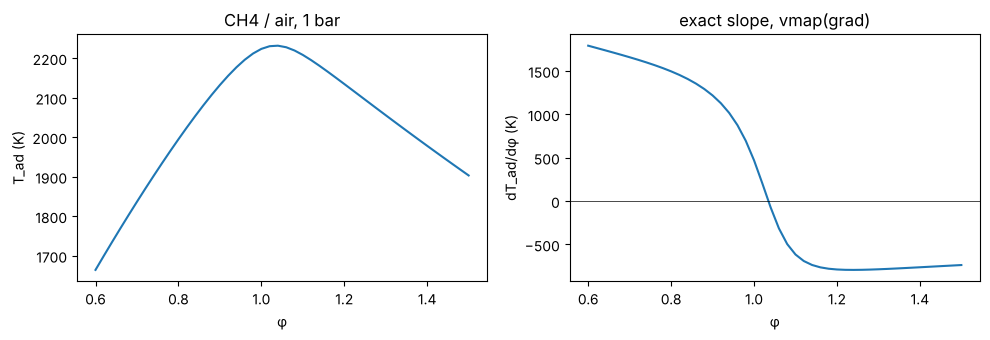

In [7]:
FLAME = ["CH4", "O2", "N2", "H2O", "CO2", "CO", "H2", "OH", "H", "O", "NO"]
th_flame = GaspypeThermo(FLAME)
burner = GibbsReactor(GibbsReactorParams(thermo=th_flame, mode="adiabatic"))

def T_ad(phi):
    o2 = 2.0 / phi
    out, info = burner(make_stream({"CH4": 1.0, "O2": o2, "N2": 3.76 * o2}, T=298.15, P=1e5))
    return info["T"]

phis = jnp.linspace(0.6, 1.5, 46)
T_curve = jax.jit(jax.vmap(T_ad))(phis)
dT_curve = jax.jit(jax.vmap(jax.grad(T_ad)))(phis)
i_max = int(jnp.argmax(T_curve))
print(f"peak T_ad = {float(T_curve[i_max]):.0f} K at phi = {float(phis[i_max]):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(phis, T_curve); ax[0].set(xlabel="φ", ylabel="T_ad (K)", title="CH4 / air, 1 bar")
ax[1].plot(phis, dT_curve); ax[1].axhline(0, color="k", lw=0.5)
ax[1].set(xlabel="φ", ylabel="dT_ad/dφ (K)", title="exact slope, vmap(grad)")
plt.tight_layout(); plt.show()

## 6. Reformer + shift, optimised by gradient

A two-reactor train: an isothermal reformer at `T_ref`, then a water-gas-shift
reactor at 600 K that is limited to the shift reaction
(`reactions=[{"CO": -1, "H2O": -1, "CO2": 1, "H2": 1}]`). Methane that slips past the
reformer does not react in the shift.

The objective is a toy margin per mol/s of methane: H2 product, minus the reformer
heat duty and the steam raised, both priced in H2-equivalents. The design variables
are `T_ref` and S/C. The gradient comes from `jax.value_and_grad` through both
equilibrium solves, and a few Adam steps are enough.

T_ref = 1024.7 K, S/C = 2.619, margin = 2.5414 mol H2 per mol CH4
gradient at the end: [ 7.03142636e-09 -1.32525848e-04]


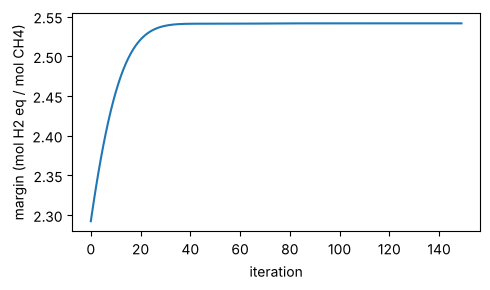

In [8]:
shift = GibbsReactor(GibbsReactorParams(thermo=th, T_out=600.0,
                                        reactions=[{"CO": -1, "H2O": -1, "CO2": 1, "H2": 1}]))
C_HEAT = 1.0 / 286e3      # mol H2 per J of reformer duty (H2 HHV)
C_STEAM = 0.15            # mol H2 per mol steam raised

def margin(x):
    T_ref, S_C = x
    out1, info1 = GibbsReactor(GibbsReactorParams(thermo=th, T_out=T_ref))(
        make_stream({"CH4": 1.0, "H2O": S_C}, T=800.0, P=1e5))
    out2, _ = shift(out1)
    return out2["F_H2"] - C_HEAT * info1["heat_duty"] - C_STEAM * S_C

vg = jax.jit(jax.value_and_grad(margin))
x = jnp.array([950.0, 2.0])
scale = jnp.array([50.0, 0.5])          # step sizes in each variable's own units
m, v = jnp.zeros(2), jnp.zeros(2)
hist = []
for k in range(1, 151):                 # Adam on the scaled variables (ascent)
    f, g = vg(x)
    g = g * scale
    m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g**2
    step = (m / (1 - 0.9**k)) / (jnp.sqrt(v / (1 - 0.999**k)) + 1e-12)
    x = x + 0.05 * scale * step
    hist.append(float(f))
f, g = vg(x)
print(f"T_ref = {float(x[0]):.1f} K, S/C = {float(x[1]):.3f}, margin = {float(f):.4f} mol H2 per mol CH4")
print("gradient at the end:", np.asarray(g))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(hist); ax.set(xlabel="iteration", ylabel="margin (mol H2 eq / mol CH4)"); plt.tight_layout(); plt.show()

## Summary

- **Gaspype can be used with difflow.** `difflow.gaspype_import.GaspypeThermo`
  adapts its gas-phase species database to `GibbsReactor` in a few lines. The
  equilibria match gaspype's own solver, and the gradients compile.
- **Gaspype's own JAX solver** is fine for forward sweeps and eager `jax.grad`.
  It cannot be differentiated under `jax.jit`, because of its `while_loop`. Use the
  adapter wherever difflow needs a gradient.
- **What the adapter does not cover.** It is ideal gas only. Gaspype has no
  liquids in a `fluid`, no VLE and no critical properties. It does have condensed
  species for activity calculations, but the adapter does not use them. The
  default `"nasa9"` path reads gaspype's private database reader, so a future
  gaspype release could move it. `method="table"` uses only the public API, but
  its T derivatives are piecewise constant.